# **Assignment 4**


**Anja Pijak**  
ap72051@student.uni-lj.si


In [21]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_val_score 

#### Data preparation


In [2]:
df = pd.read_csv("datasets/House_Price.csv")

df.head()




,price,crime_rate,resid_area,air_qual,room_num,age,dist1,dist2,dist3,dist4,teachers,poor_prop,airport,n_hos_beds,n_hot_rooms,waterbody,rainfall,bus_ter,parks
0,24.0,0.00632,32.31,0.538,6.575,65.2,4.35,3.81,4.18,4.01,24.7,4.98,YES,5.480,11.1920,River,23,YES,0.049347
1,21.6,0.02731,37.07,0.469,6.421,78.9,4.99,4.70,5.12,5.06,22.2,9.14,NO,7.332,12.1728,Lake,42,YES,0.046146
2,34.7,0.02729,37.07,0.469,7.185,61.1,5.03,4.86,5.01,4.97,22.2,4.03,NO,7.394,101.1200,NaN,38,YES,0.045764
3,33.4,0.03237,32.18,0.458,6.998,45.8,6.21,5.93,6.16,5.96,21.3,2.94,YES,9.268,11.2672,Lake,45,YES,0.047151
4,36.2,0.06905,32.18,0.458,7.147,54.2,6.16,5.86,6.37,5.86,21.3,5.33,NO,8.824,11.2896,Lake,55,YES,0.039474


In [37]:
X = df.loc[:, df.columns != 'price'] # attributes
y = df['price'] # target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)



# Fill missing values for all columns except string columns
columns_to_fill = X_train.columns.difference(["waterbody", "bus_ter", "airport"])

X_train[columns_to_fill] = X_train[columns_to_fill].fillna(X_train[columns_to_fill].mean())
X_test[columns_to_fill] = X_test[columns_to_fill].fillna(X_train[columns_to_fill].mean())  # Use X_train mean for consistency

# Encode categorical variables
X_train['waterbody'] = X_train['waterbody'].apply(lambda x: 1 if x == "River" else 0)
X_test['waterbody'] = X_test['waterbody'].apply(lambda x: 1 if x == "River" else 0)

X_train['bus_ter'] = X_train['bus_ter'].apply(lambda x: 1 if x == "YES" else 0)
X_test['bus_ter'] = X_test['bus_ter'].apply(lambda x: 1 if x == "YES" else 0)

X_train['airport'] = X_train['airport'].apply(lambda x: 1 if x == "YES" else 0)
X_test['airport'] = X_test['airport'].apply(lambda x: 1 if x == "YES" else 0)

# print((X_train['waterbody'] == "River").sum()/X_train.shape[0])

# # I get 36% River and the rest Lake from train set so I will impute Lake as a value for na
# X_train['waterbody'] = X_train['waterbody'].fillna("Lake")
# X_test['waterbody'] = X_test['waterbody'].fillna("Lake")


In [41]:
class RegressionTree:
    def __init__(self, max_depth=None, min_samples_split=2):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.tree = None

    def fit(self, X, y):
        self.tree = self._grow_tree(X, y)

    def _grow_tree(self, X, y, depth=0):
        n_samples, n_features = X.shape
        if n_samples < self.min_samples_split or (self.max_depth is not None and depth >= self.max_depth):
            leaf_value = np.mean(y)
            return {"leaf": leaf_value}

        best_split = self._find_best_split(X, y)
        left_tree = self._grow_tree(X[best_split["left_indices"]], y[best_split["left_indices"]], depth + 1)
        right_tree = self._grow_tree(X[best_split["right_indices"]], y[best_split["right_indices"]], depth + 1)
        return {"feature": best_split["feature"], "threshold": best_split["threshold"], "left": left_tree, "right": right_tree}

    def _find_best_split(self, X, y):
        n_samples, n_features = X.shape
        best_rss = float("inf")
        best_split = {}

        for feature_index in range(n_features):
            thresholds = np.unique(X[:, feature_index])
            for threshold in thresholds:
                left_indices = X[:, feature_index] <= threshold
                right_indices = X[:, feature_index] > threshold
                if len(left_indices) == 0 or len(right_indices) == 0:
                    continue
                rss = self._calculate_rss(y[left_indices], y[right_indices])
                if rss < best_rss:
                    best_rss = rss
                    best_split = {"feature": feature_index, "threshold": threshold, "left_indices": left_indices, "right_indices": right_indices}
        return best_split

    def _calculate_rss(self, left_y, right_y):
        left_rss = np.sum((left_y - np.mean(left_y)) ** 2)
        right_rss = np.sum((right_y - np.mean(right_y)) ** 2)
        return left_rss + right_rss

    def predict(self, X):
        return np.array([self._predict(sample, self.tree) for sample in X])

    def _predict(self, sample, tree):
        if "leaf" in tree:
            return tree["leaf"]
        feature_index = tree["feature"]
        threshold = tree["threshold"]
        if sample[feature_index] <= threshold:
            return self._predict(sample, tree["left"])
        else:
            return self._predict(sample, tree["right"])


In [20]:

tree = RegressionTree(max_depth=4, min_samples_split=10)
tree.fit(X_train.values, y_train.values)  # Ensure using numpy arrays

# Make predictions
y_pred = tree.predict(X_test.values)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print(mae, mse)


c:\Users\EC\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\EC\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


2.7090087970863514 12.28399143741182


c:\Users\EC\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\EC\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
c:\Users\EC\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\EC\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
c:\Users\EC\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\EC\AppData\Local\Programs\Py

    max_depth  min_samples_split  mean_mae   mean_mse
0           3                  2  3.543018  30.631189
1           3                  5  3.543018  30.631189
2           3                 10  3.543018  30.631189
3           5                  2  3.200678  29.220025
4           5                  5  3.226421  30.267074
5           5                 10  3.249879  31.047471
6           7                  2  3.409360  30.570848
7           7                  5  3.441665  31.790700
8           7                 10  3.452812  32.632621
9           9                  2  3.488149  31.130744
10          9                  5  3.495171  32.159530
11          9                 10  3.466486  32.882264
12         11                  2  3.483131  31.374891
13         11                  5  3.478296  32.229277
14         11                 10  3.449244  32.887388


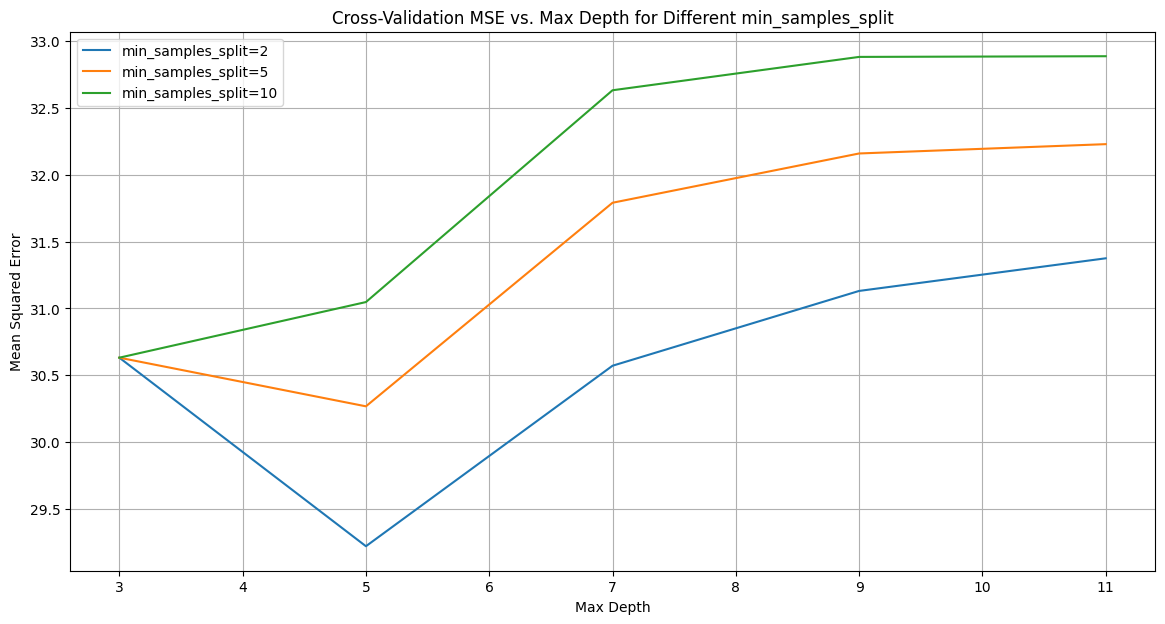

In [42]:
# Perform cross-validation with different stopping criteria
kf = KFold(n_splits=5, shuffle=True, random_state=42)
max_depth_values = [3, 5, 7, 9, 11]
min_samples_split_values = [2, 5, 10]

results = []

for max_depth in max_depth_values:
    for min_samples_split in min_samples_split_values:
        mae_scores = []
        mse_scores = []

        for train_index, val_index in kf.split(X_train):
            X_train_cv, X_val_cv = X_train.values[train_index], X_train.values[val_index]
            y_train_cv, y_val_cv = y_train.values[train_index], y_train.values[val_index]

            tree = RegressionTree(max_depth=max_depth, min_samples_split=min_samples_split)
            tree.fit(X_train_cv, y_train_cv)
            y_pred_cv = tree.predict(X_val_cv)
            
            mae_scores.append(mean_absolute_error(y_val_cv, y_pred_cv))
            mse_scores.append(mean_squared_error(y_val_cv, y_pred_cv))

        mean_mae = np.mean(mae_scores)
        mean_mse = np.mean(mse_scores)
        results.append((max_depth, min_samples_split, mean_mae, mean_mse))

# Display the results
results_df = pd.DataFrame(results, columns=['max_depth', 'min_samples_split', 'mean_mae', 'mean_mse'])
print(results_df)

# Plot the results to observe overfitting
plt.figure(figsize=(14, 7))
for min_samples_split in min_samples_split_values:
    subset = results_df[results_df['min_samples_split'] == min_samples_split]
    plt.plot(subset['max_depth'], subset['mean_mse'], label=f'min_samples_split={min_samples_split}')

plt.xlabel('Max Depth')
plt.ylabel('Mean Squared Error')
plt.title('Cross-Validation MSE vs. Max Depth for Different min_samples_split')
plt.legend()
plt.grid(True)
plt.show()


c:\Users\EC\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\EC\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
c:\Users\EC\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\EC\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
c:\Users\EC\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\EC\AppData\Local\Programs\Py

    max_depth  min_samples_split  mean_mae_custom  mean_mse_custom  \
0           3                  2         3.543018        30.631189   
1           3                  5         3.543018        30.631189   
2           3                 10         3.543018        30.631189   
3           5                  2         3.200678        29.220025   
4           5                  5         3.226421        30.267074   
5           5                 10         3.249879        31.047471   
6           7                  2         3.409360        30.570848   
7           7                  5         3.441665        31.790700   
8           7                 10         3.452812        32.632621   
9           9                  2         3.488149        31.130744   
10          9                  5         3.495171        32.159530   
11          9                 10         3.466486        32.882264   
12         11                  2         3.483131        31.374891   
13         11       

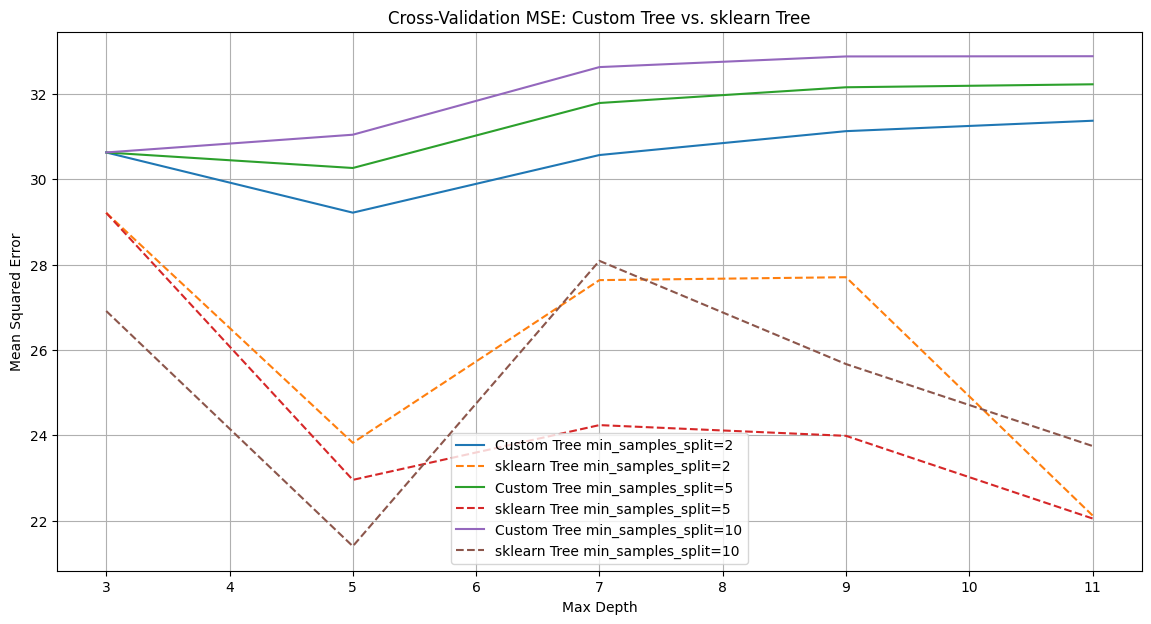

In [43]:
from sklearn.tree import DecisionTreeRegressor

# Cross-validation with custom regression tree
kf = KFold(n_splits=5, shuffle=True, random_state=42)
max_depth_values = [3, 5, 7, 9, 11]
min_samples_split_values = [2, 5, 10]

results_custom = []

for max_depth in max_depth_values:
    for min_samples_split in min_samples_split_values:
        mae_scores_custom = []
        mse_scores_custom = []

        for train_index, val_index in kf.split(X_train):
            X_train_cv, X_val_cv = X_train.values[train_index], X_train.values[val_index]
            y_train_cv, y_val_cv = y_train.values[train_index], y_train.values[val_index]

            tree = RegressionTree(max_depth=max_depth, min_samples_split=min_samples_split)
            tree.fit(X_train_cv, y_train_cv)
            y_pred_cv = tree.predict(X_val_cv)
            
            mae_scores_custom.append(mean_absolute_error(y_val_cv, y_pred_cv))
            mse_scores_custom.append(mean_squared_error(y_val_cv, y_pred_cv))

        mean_mae_custom = np.mean(mae_scores_custom)
        mean_mse_custom = np.mean(mse_scores_custom)
        results_custom.append((max_depth, min_samples_split, mean_mae_custom, mean_mse_custom))

# Cross-validation with scikit-learn regression tree
results_sklearn = []

for max_depth in max_depth_values:
    for min_samples_split in min_samples_split_values:
        mae_scores_sklearn = []
        mse_scores_sklearn = []

        for train_index, val_index in kf.split(X_train):
            X_train_cv, X_val_cv = X_train.values[train_index], X_train.values[val_index]
            y_train_cv, y_val_cv = y_train.values[train_index], y_train.values[val_index]

            sklearn_tree = DecisionTreeRegressor(max_depth=max_depth, min_samples_split=min_samples_split)
            sklearn_tree.fit(X_train_cv, y_train_cv)
            y_pred_cv_sklearn = sklearn_tree.predict(X_val_cv)
            
            mae_scores_sklearn.append(mean_absolute_error(y_val_cv, y_pred_cv_sklearn))
            mse_scores_sklearn.append(mean_squared_error(y_val_cv, y_pred_cv_sklearn))

        mean_mae_sklearn = np.mean(mae_scores_sklearn)
        mean_mse_sklearn = np.mean(mse_scores_sklearn)
        results_sklearn.append((max_depth, min_samples_split, mean_mae_sklearn, mean_mse_sklearn))

# Display the results
results_custom_df = pd.DataFrame(results_custom, columns=['max_depth', 'min_samples_split', 'mean_mae_custom', 'mean_mse_custom'])
results_sklearn_df = pd.DataFrame(results_sklearn, columns=['max_depth', 'min_samples_split', 'mean_mae_sklearn', 'mean_mse_sklearn'])

# Merge both results for comparison
results_comparison_df = results_custom_df.merge(results_sklearn_df, on=['max_depth', 'min_samples_split'])
print(results_comparison_df)

# Plot the results to compare
plt.figure(figsize=(14, 7))
for min_samples_split in min_samples_split_values:
    subset = results_comparison_df[results_comparison_df['min_samples_split'] == min_samples_split]
    plt.plot(subset['max_depth'], subset['mean_mse_custom'], label=f'Custom Tree min_samples_split={min_samples_split}')
    plt.plot(subset['max_depth'], subset['mean_mse_sklearn'], linestyle='--', label=f'sklearn Tree min_samples_split={min_samples_split}')

plt.xlabel('Max Depth')
plt.ylabel('Mean Squared Error')
plt.title('Cross-Validation MSE: Custom Tree vs. sklearn Tree')
plt.legend()
plt.grid(True)
plt.show()


c:\Users\EC\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\EC\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
c:\Users\EC\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\EC\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
c:\Users\EC\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\EC\AppData\Local\Programs\Py

    max_depth  min_samples_split  mean_mae_custom  mean_mse_custom  \
0           3                  2         3.543018        30.631189   
1           3                  5         3.543018        30.631189   
2           3                 10         3.543018        30.631189   
3           5                  2         3.200678        29.220025   
4           5                  5         3.226421        30.267074   
5           5                 10         3.249879        31.047471   
6           7                  2         3.409360        30.570848   
7           7                  5         3.441665        31.790700   
8           7                 10         3.452812        32.632621   
9           9                  2         3.488149        31.130744   
10          9                  5         3.495171        32.159530   
11          9                 10         3.466486        32.882264   
12         11                  2         3.483131        31.374891   
13         11       

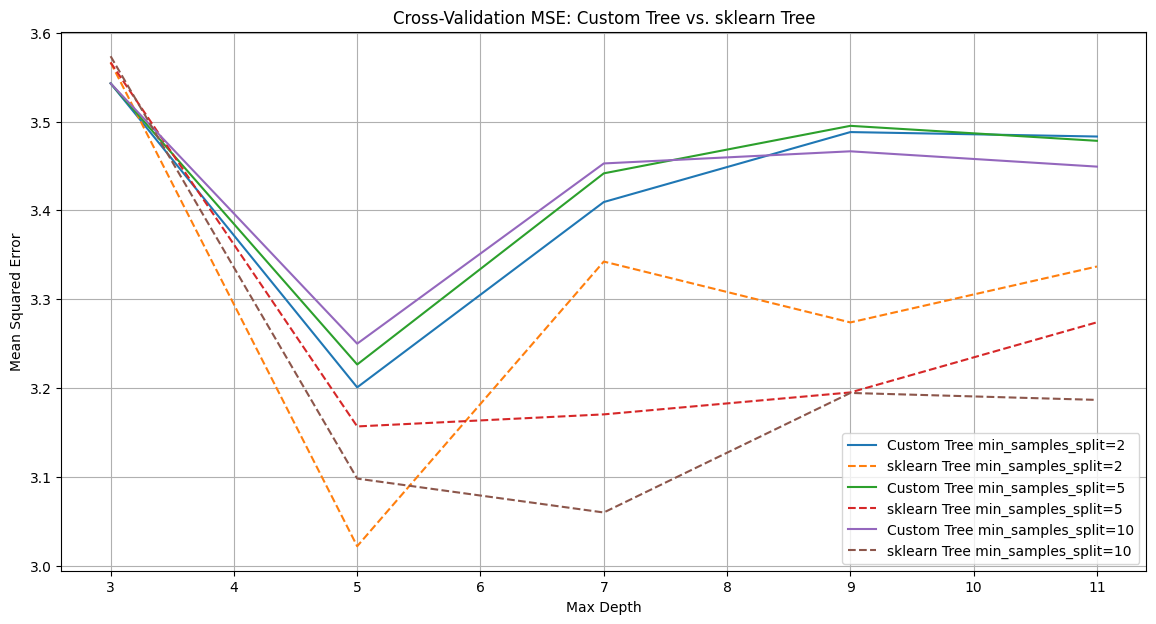

In [44]:
# Proceed with cross-validation and model comparison
kf = KFold(n_splits=5, shuffle=True, random_state=42)
max_depth_values = [3, 5, 7, 9, 11]
min_samples_split_values = [2, 5, 10]

results_custom = []
results_sklearn = []

for max_depth in max_depth_values:
    for min_samples_split in min_samples_split_values:
        mae_scores_custom = []
        mse_scores_custom = []
        mae_scores_sklearn = []
        mse_scores_sklearn = []

        for train_index, val_index in kf.split(X_train):
            X_train_cv, X_val_cv = X_train.values[train_index], X_train.values[val_index]
            y_train_cv, y_val_cv = y_train.values[train_index], y_train.values[val_index]

            # Custom regression tree
            custom_tree = RegressionTree(max_depth=max_depth, min_samples_split=min_samples_split)
            custom_tree.fit(X_train_cv, y_train_cv)
            y_pred_cv_custom = custom_tree.predict(X_val_cv)
            
            mae_scores_custom.append(mean_absolute_error(y_val_cv, y_pred_cv_custom))
            mse_scores_custom.append(mean_squared_error(y_val_cv, y_pred_cv_custom))

            # Scikit-learn regression tree
            sklearn_tree = DecisionTreeRegressor(max_depth=max_depth, min_samples_split=min_samples_split)
            sklearn_tree.fit(X_train_cv, y_train_cv)
            y_pred_cv_sklearn = sklearn_tree.predict(X_val_cv)
            
            mae_scores_sklearn.append(mean_absolute_error(y_val_cv, y_pred_cv_sklearn))
            mse_scores_sklearn.append(mean_squared_error(y_val_cv, y_pred_cv_sklearn))

        mean_mae_custom = np.mean(mae_scores_custom)
        mean_mse_custom = np.mean(mse_scores_custom)
        results_custom.append((max_depth, min_samples_split, mean_mae_custom, mean_mse_custom))

        mean_mae_sklearn = np.mean(mae_scores_sklearn)
        mean_mse_sklearn = np.mean(mse_scores_sklearn)
        results_sklearn.append((max_depth, min_samples_split, mean_mae_sklearn, mean_mse_sklearn))

# Display the results
results_custom_df = pd.DataFrame(results_custom, columns=['max_depth', 'min_samples_split', 'mean_mae_custom', 'mean_mse_custom'])
results_sklearn_df = pd.DataFrame(results_sklearn, columns=['max_depth', 'min_samples_split', 'mean_mae_sklearn', 'mean_mse_sklearn'])

# Merge both results for comparison
results_comparison_df = results_custom_df.merge(results_sklearn_df, on=['max_depth', 'min_samples_split'])
print(results_comparison_df)

# Plot the results to compare
plt.figure(figsize=(14, 7))
for min_samples_split in min_samples_split_values:
    subset = results_comparison_df[results_comparison_df['min_samples_split'] == min_samples_split]
    plt.plot(subset['max_depth'], subset['mean_mae_custom'], label=f'Custom Tree min_samples_split={min_samples_split}')
    plt.plot(subset['max_depth'], subset['mean_mae_sklearn'], linestyle='--', label=f'sklearn Tree min_samples_split={min_samples_split}')

plt.xlabel('Max Depth')
plt.ylabel('Mean Squared Error')
plt.title('Cross-Validation MSE: Custom Tree vs. sklearn Tree')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
from tabulate import tabulate

# Perform cross-validation with different stopping criteria for both models
kf = KFold(n_splits=5, shuffle=True, random_state=42)
max_depth_values = [3, 5, 7, 9, 11]
min_samples_split_values = [2, 5, 10]

results = []

for max_depth in max_depth_values:
    for min_samples_split in min_samples_split_values:
        mae_scores_custom = []
        mae_scores_sklearn = []

        for train_index, val_index in kf.split(X_train):
            X_train_cv, X_val_cv = X_train.values[train_index], X_train.values[val_index]
            y_train_cv, y_val_cv = y_train.values[train_index], y_train.values[val_index]

            # Custom regression tree
            custom_tree = RegressionTree(max_depth=max_depth, min_samples_split=min_samples_split)
            custom_tree.fit(X_train_cv, y_train_cv)
            y_pred_cv_custom = custom_tree.predict(X_val_cv)
            mae_custom = mean_absolute_error(y_val_cv, y_pred_cv_custom)
            mae_scores_custom.append(mae_custom)

            # Scikit-learn regression tree
            sklearn_tree = DecisionTreeRegressor(max_depth=max_depth, min_samples_split=min_samples_split)
            sklearn_tree.fit(X_train_cv, y_train_cv)
            y_pred_cv_sklearn = sklearn_tree.predict(X_val_cv)
            mae_sklearn = mean_absolute_error(y_val_cv, y_pred_cv_sklearn)
            mae_scores_sklearn.append(mae_sklearn)

        mean_mae_custom = np.mean(mae_scores_custom)
        mean_mae_sklearn = np.mean(mae_scores_sklearn)
        results.append({
            "max_depth": max_depth,
            "min_samples_split": min_samples_split,
            "MAE (Custom)": mean_mae_custom,
            "MAE (scikit-learn)": mean_mae_sklearn
        })


c:\Users\EC\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\EC\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
c:\Users\EC\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\EC\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
c:\Users\EC\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\EC\AppData\Local\Programs\Py

In [46]:
# Print results as a table
print(tabulate(results, headers="keys", tablefmt="grid"))


+-------------+---------------------+----------------+----------------------+
|   max_depth |   min_samples_split |   MAE (Custom) |   MAE (scikit-learn) |
+=============+=====================+================+======================+
|           3 |                   2 |        3.54302 |              3.57356 |
+-------------+---------------------+----------------+----------------------+
|           3 |                   5 |        3.54302 |              3.52503 |
+-------------+---------------------+----------------+----------------------+
|           3 |                  10 |        3.54302 |              3.57356 |
+-------------+---------------------+----------------+----------------------+
|           5 |                   2 |        3.20068 |              3.10202 |
+-------------+---------------------+----------------+----------------------+
|           5 |                   5 |        3.22642 |              3.12397 |
+-------------+---------------------+----------------+----------